In [1]:
!pip install git+https://github.com/peterbarkley/oars.git@development

zsh:1: command not found: pip


In [2]:
import numpy as np
from oars.algorithms.cara import caraAlgorithm
from scipy.spatial import HalfspaceIntersection, ConvexHull
from scipy.optimize import linprog
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

The caraAlgorithm implementation requires a list of prox classes, a list of data dictionaries for each prox class, and lists of Z and W matrices for each variable element, where the dimensions of Z and W for variable $k$ match the number of data dictionaries where $k$ appears in the varlist. Our variables are numbered 0 through $p-1$.

This is a sample prox class for CARA. It must have a prox function taking an input $y$ and $\alpha$ scaling parameter. It must also have vars, indices, and shape parameters. CARA will expect a varlist argument for each data dictionary (which will be stored in the vars parameter for the prox class). Indices will be set by CARA, and shape will be used by CARA to set the shape of the iterates for the prox. If the variable shape is (1,) for each variable in the varlist, this shape will be len(varlist).

In [3]:

class halfspaceProj():
    """
    Warped projection onto the halfspace defined by
    c^T x >= v
    """
    def __init__(self, c=-np.ones(2), v=-1,  D=np.ones(2), indices=[0,1], varlist=[0,1]):
        self.vars = varlist # Required - list of the variables that the prox uses
        self.indices = indices # Required - the indices of the variable(s) in the entire variable array
        self.c = c
        self.Di = D**(-1)
        self.u = self.Di*c/(c @ (self.Di*c))
        self.v = v

    def prox(self, y, alpha, **kwargs):

        Diy = self.Di * y
        t = self.c@Diy - self.v
        if t < 0.0:
            return Diy - t*self.u
        return Diy


### This first example finds a point in the intersection of two halfspaces.

$$0.05x_1 - x_2 \geq 2$$
$$0.05x_1 + x_2 \geq 2$$

We use a connected graph on two points to define $Z$ for each variable, with identical scaling for each.

In [4]:
p = 2 # number of variables
n = 2 # number of halfspaces
Zf = np.array([[1.,-1, ],
               [-1, 1, ]]) # Matrix governing the data sharing in the prox step (we set W = Z as well)
Zs = [Zf.copy() for _ in range(p)] # We create a matrix for each variable, but they are all the same in this example
c = np.array([[0.05, -1],
              [0.05, 1]]) # Halfspace normals
v = np.array([2, 2]) # Halfspace offsets
varlist = list(range(p)) # List of variable indices (0, 1, ..., p-1) - this is used to determine which variables are updated by each halfspace projection. In this example, each halfspace projection updates both variables, so we use the full list of variable indices.

In [5]:
# Plotting functions
def fill_intersection(c, v, ax, colors, xlim=(0, 100), ylim=(-5, 5)):
    """
    Calculates and plots the feasible intersection region of multiple halfspaces.
    """
    halfspaces = np.column_stack((-c, v))
    
    # Add a bounding box
    box = np.array([
        [1, 0, -xlim[1]],   
        [-1, 0, xlim[0]],  
        [0, 1, -ylim[1]], 
        [0, -1, ylim[0]]  
    ])
    halfspaces = np.vstack([halfspaces, box])
    
    # Find a feasible interior point strictly inside the region
    a_ub = halfspaces[:, :2]
    b_ub = -halfspaces[:, 2]
    a_lp = np.column_stack((a_ub, np.ones(len(a_ub))))
    c_lp = [0, 0, -1]  # Minimize -s (which maximizes our safety margin s)
    
    res = linprog(c_lp, A_ub=a_lp, b_ub=b_ub, bounds=[xlim, ylim, (0, None)])
    
    # If a valid interior point exists, calculate and fill the intersection
    if res.success and res.x[2] > 1e-5:
        interior_point = res.x[:2]
        hs = HalfspaceIntersection(halfspaces, interior_point)
        
        # ConvexHull sorts the vertices counter-clockwise so matplotlib fills the polygon correctly
        hull = ConvexHull(hs.intersections)
        ordered_vertices = hs.intersections[hull.vertices]
        
        ax.fill(ordered_vertices[:, 0], ordered_vertices[:, 1], 
                color='green', alpha=0.3, label='Intersection')
    else:
        print("No feasible intersection region found with a valid interior.")

    # Plot the boundary lines
    xx = np.linspace(xlim[0], xlim[1], 100)
    for i in range(len(c)):
        if abs(c[i][1]) > 1e-7:
            y = (v[i] - c[i][0] * xx) / c[i][1]
            ax.plot(xx, y, color=colors[i], linestyle='--', 
                    linewidth=2, label=f'Constraint {i+1}')
        else:
            # Robustly handle vertical lines where c[i][1] == 0 to prevent division by zero
            x_val = v[i] / c[i][0]
            ax.axvline(x=x_val, color=colors[i], linestyle='--', 
                       linewidth=2, label=f'Constraint {i+1}')
    return ax


def plot_data(c, v, data, xlim=(0, 100), ylim=(-5, 5), limit=20, stride=1):
    """
    Plots the data points over iterations along with the intersection region.
    """
    cmap = plt.get_cmap('tab10')
    colors = [cmap(i % 10) for i in range(len(v))]
    fig, ax = plt.subplots(figsize=(10, 4))
    
    # Plot region
    ax = fill_intersection(c, v, ax, colors, xlim, ylim)
    
    # Plot points
    for i, all_x in enumerate(data):
        for itr, x in enumerate(all_x[:limit]):
            if itr == 0:
                ax.scatter(x[0], x[1], color=colors[i], label=f'Prox {i+1}')     
                ax.annotate(f'{itr}', x) 
            elif itr % stride == 0:
                ax.scatter(x[0], x[1], color=colors[i])    
                ax.annotate(f'{itr}', x)
                
    ax.set_ylabel('y')
    ax.set_xlabel('x')
    if ylim is not None:
        ax.set_ylim(ylim)
        
    ax.legend(loc='upper right')
    
    return fig


class CbPlot:
    """
    Callback class to store point data per iteration for plotting.
    """
    def __init__(self, n):
        self.data = [[] for _ in range(n)]
        self.n = n

    def __call__(self, all_x, *args, **kwargs):
        """
        Store x values for a given iteration.
        
        Args:
            all_x: n by 2 numpy array of points
        """
        for i in range(self.n):
            self.data[i].append(all_x[i].copy())
            

date		time		itr	||x-bar(x)||	||sum dual||
2026-11-02 13:51:05.333447	1	2.811e+00	3.975e+00
2026-11-02 13:51:05.333529	3	2.790e+00	3.945e+00
2026-11-02 13:51:05.333592	5	2.769e+00	3.916e+00
2026-11-02 13:51:05.333651	7	2.748e+00	3.887e+00
2026-11-02 13:51:05.333720	9	2.728e+00	3.858e+00
2026-11-02 13:51:05.333776	11	2.707e+00	3.829e+00
2026-11-02 13:51:05.333833	13	2.687e+00	3.800e+00
2026-11-02 13:51:05.333887	15	2.667e+00	3.772e+00
2026-11-02 13:51:05.333943	17	2.647e+00	3.744e+00
2026-11-02 13:51:05.334000	19	2.628e+00	3.716e+00
2026-11-02 13:51:05.334051	21	0.000e+00	0.000e+00
2026-11-02 13:51:05.334103	23	0.000e+00	0.000e+00


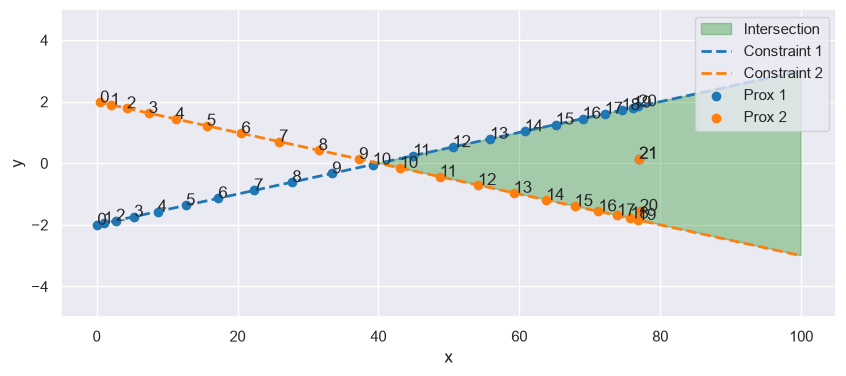

In [6]:

data = [{'c':c[i], 'v':v[i], 'varlist':varlist} for i in range(n)] # Data for each halfspace projection, including the halfspace normal, offset, preconditioner, and variable indices
A = [halfspaceProj for _ in range(n)] # List of halfspace projection classes, one for each halfspace
cbpc = CbPlot(n) # Callback to store the iterates for plotting
xbar, all_x, all_v = caraAlgorithm(data=data, A=A, W=Zs, Z=Zs, itrs=25, callback=cbpc, gamma=1.5, verbose=True) 
fig = plot_data(c, v, cbpc.data, ylim=(-5, 5), limit=22)

Now we change the scaling so that the x-axis coefficients are stretched relative to the y-axis coefficients.
This acts to makes the boundaries more perpendicular to one another in the warped space, and speeds the rate of convergence

date		time		itr	||x-bar(x)||	||sum dual||
2026-11-02 13:51:05.474773	0	2.828e+01	1.000e-01
2026-11-02 13:51:05.474834	1	0.000e+00	0.000e+00
2026-11-02 13:51:05.474884	2	0.000e+00	0.000e+00


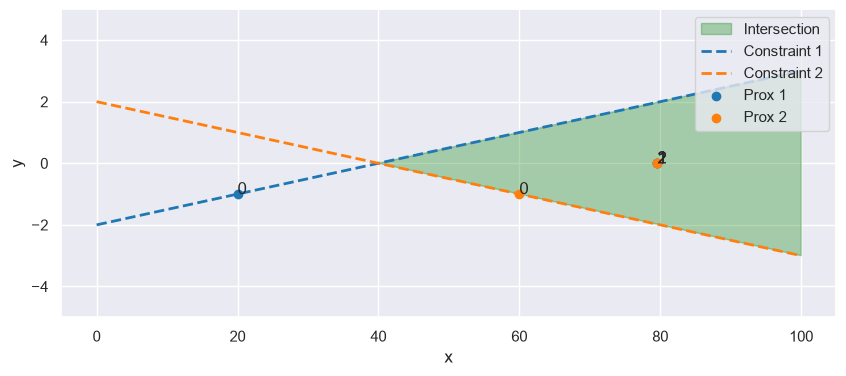

In [ ]:
Zs = [0.0025*Zf, Zf]
data = [{'c':c[i], 'v':v[i], 'varlist':varlist} for i in range(n)]
A = [halfspaceProj for _ in range(n)]
cbpc = CbPlot(n)
xbar, all_x, all_v = caraAlgorithm(data=data, A=A, W=Zs, Z=Zs, itrs=3, callback=cbpc, gamma=1.99, verbose=True)
fig = plot_data(c, v, cbpc.data)

Now we work over the intersection of 3 halfspaces, using the graph Laplacian of the complete graph for each $Z_k$

In [ ]:
p = 2
n = 3
Zf = np.array([[2.,-1, -1],
               [-1, 2, -1],
               [-1, -1, 2]])
Zs = [Zf.copy() for _ in range(p)]
c = np.array([[0.05, -1],
           [0.05, 1],
           [0.01, 1]])
v = np.array([2, 2, -1])
varlist = list(range(p))
data = [{'c':c[i], 'v':v[i], 'varlist':varlist} for i in range(n)]
A = [halfspaceProj for _ in range(n)]
cbpc_three = CbPlot(n)
xbar, all_x, all_v = caraAlgorithm(data=data, A=A, W=Zs, Z=Zs, itrs=50, callback=cbpc_three, gamma=1.5, verbose=True)

date		time		itr	||x-bar(x)||	||sum dual||
2026-11-02 13:51:05.531481	4	2.799e+00	5.234e+00
2026-11-02 13:51:05.531636	9	2.769e+00	7.167e+00
2026-11-02 13:51:05.531778	14	2.740e+00	7.733e+00
2026-11-02 13:51:05.531916	19	2.712e+00	6.563e+00
2026-11-02 13:51:05.532054	24	2.683e+00	4.468e+00
2026-11-02 13:51:05.532208	29	9.364e-02	0.000e+00
2026-11-02 13:51:05.532358	34	2.926e-03	0.000e+00
2026-11-02 13:51:05.532501	39	9.145e-05	0.000e+00
2026-11-02 13:51:05.532651	44	2.858e-06	0.000e+00
2026-11-02 13:51:05.532787	49	8.930e-08	0.000e+00


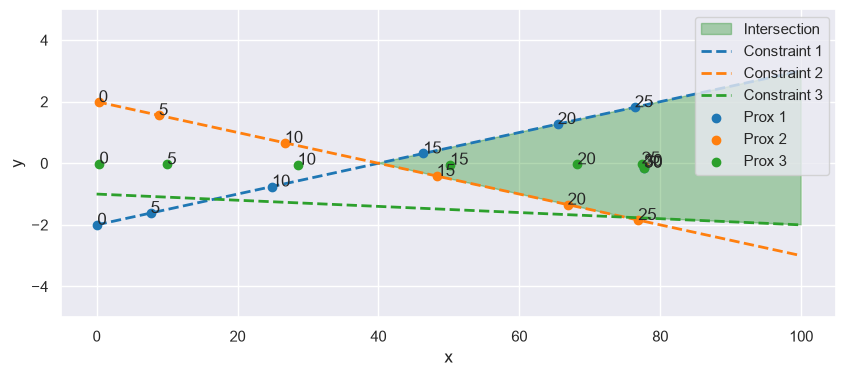

In [9]:
fig = plot_data(c, v, cbpc_three.data, ylim=(-5, 5), limit=34, stride=5)
fig.savefig('three_ops_unscaled.pdf', bbox_inches='tight')

Now we again skew the spaces.

date		time		itr	||x-bar(x)||	||sum dual||
2026-11-02 13:51:05.725253	0	2.830e+01	2.000e-01
2026-11-02 13:51:05.725330	1	7.144e+00	5.000e-02
2026-11-02 13:51:05.725393	2	3.062e-01	0.000e+00
2026-11-02 13:51:05.725509	3	1.531e-01	0.000e+00
2026-11-02 13:51:05.725635	4	7.655e-02	0.000e+00
2026-11-02 13:51:05.725738	5	3.827e-02	0.000e+00
2026-11-02 13:51:05.725805	6	1.914e-02	0.000e+00
2026-11-02 13:51:05.725904	7	9.568e-03	0.000e+00
2026-11-02 13:51:05.725969	8	4.784e-03	0.000e+00
2026-11-02 13:51:05.726042	9	2.392e-03	0.000e+00


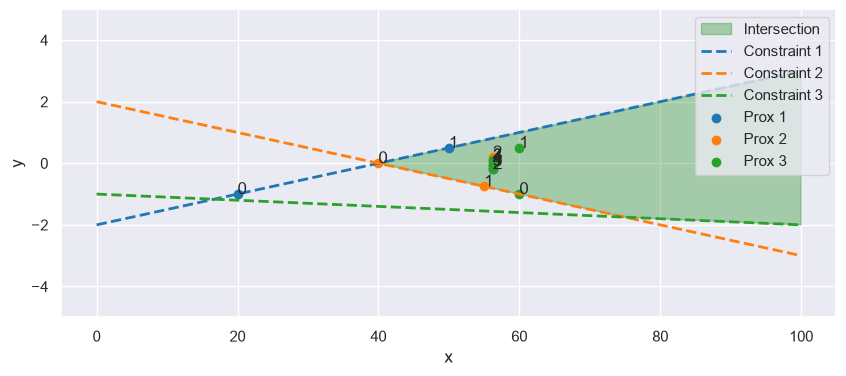

In [ ]:

Zf = np.array([[2.,-1, -1],
               [-1, 2, -1],
               [-1, -1, 2]])
Zs = [0.0025*Zf, Zf]
data = [{'c':c[i], 'v':v[i], 'varlist':varlist} for i in range(n)]
A = [halfspaceProj for _ in range(n)]
cbpc_three = CbPlot(n)
xbar, all_x, all_v = caraAlgorithm(data=data, A=A, W=Zs, Z=Zs, itrs=10, callback=cbpc_three, gamma=1.5, verbose=True)

fig = plot_data(c, v, cbpc_three.data, ylim=(-5, 5), limit=5)
fig.savefig('three_ops_scaled.pdf', bbox_inches='tight')


The remainder of the demo show that choosing $Z_k$ corresponding to a path graph performs similarly, beginning with the graph 1-2-3

In [ ]:
Zf = np.array([[1.,-1, 0],
               [-1, 2, -1],
               [0, -1, 1]])
Zs = [Zf.copy() for _ in range(p)]
data = [{'c':c[i], 'v':v[i],  'varlist':varlist} for i in range(n)]
A = [halfspaceProj for _ in range(n)]
cbpc_three = CbPlot(n)
xbar, all_x, all_v = caraAlgorithm(data=data, A=A, W=Zs, Z=Zs, itrs=50, callback=cbpc_three, gamma=1.5, verbose=True)

date		time		itr	||x-bar(x)||	||sum dual||
2026-11-02 13:51:05.841220	4	3.428e+00	4.425e+00
2026-11-02 13:51:05.841362	9	3.716e+00	5.105e+00
2026-11-02 13:51:05.841494	14	3.883e+00	5.490e+00
2026-11-02 13:51:05.841626	19	3.710e+00	5.146e+00
2026-11-02 13:51:05.841767	24	3.325e+00	4.317e+00
2026-11-02 13:51:05.841953	29	1.847e+00	1.834e+00
2026-11-02 13:51:05.842099	34	5.711e-03	0.000e+00
2026-11-02 13:51:05.842257	39	1.785e-04	0.000e+00
2026-11-02 13:51:05.842408	44	5.577e-06	0.000e+00
2026-11-02 13:51:05.842547	49	1.743e-07	0.000e+00


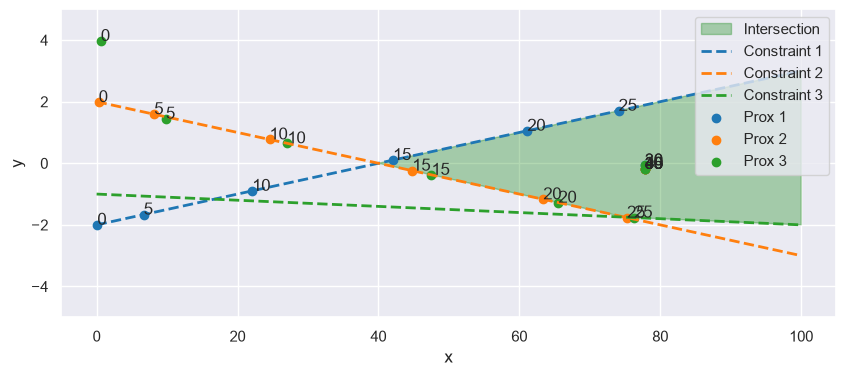

In [12]:

fig = plot_data(c, v, cbpc_three.data, ylim=(-5, 5), limit=41, stride=5)

Then we try the remaining possible paths 1-3-2, 2-1-3, 2-3-1, 3-1-2, and 3-2-1

[0, 2, 1]
date		time		itr	||x-bar(x)||	||sum dual||
2026-11-02 13:51:05.942988	4	2.808e+00	3.969e+00
2026-11-02 13:51:05.943133	9	2.794e+00	3.950e+00
2026-11-02 13:51:05.943350	14	2.781e+00	3.932e+00
2026-11-02 13:51:05.943493	19	2.768e+00	3.913e+00
2026-11-02 13:51:05.943645	24	2.755e+00	3.895e+00
2026-11-02 13:51:05.943796	29	2.743e+00	3.877e+00
2026-11-02 13:51:05.943977	34	2.730e+00	3.859e+00
2026-11-02 13:51:05.944151	39	2.717e+00	3.841e+00
2026-11-02 13:51:05.944293	44	2.069e-01	0.000e+00
2026-11-02 13:51:05.944455	49	6.466e-03	0.000e+00
[1, 0, 2]
date		time		itr	||x-bar(x)||	||sum dual||
2026-11-02 13:51:05.959080	4	3.363e+00	4.160e+00
2026-11-02 13:51:05.959238	9	3.949e+00	5.526e+00
2026-11-02 13:51:05.959370	14	3.655e+00	5.168e+00
2026-11-02 13:51:05.959520	19	3.455e+00	4.764e+00
2026-11-02 13:51:05.959657	24	3.088e+00	3.967e+00
2026-11-02 13:51:05.959820	29	7.827e-01	0.000e+00
2026-11-02 13:51:05.959982	34	2.446e-02	0.000e+00
2026-11-02 13:51:05.960108	39	7.643e-04	0.000e+00


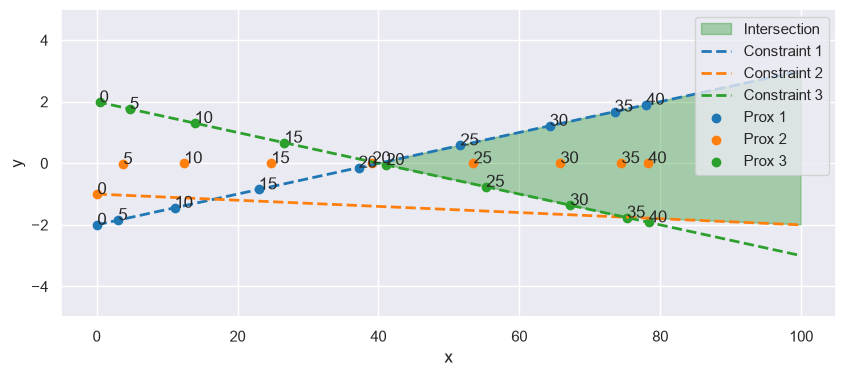

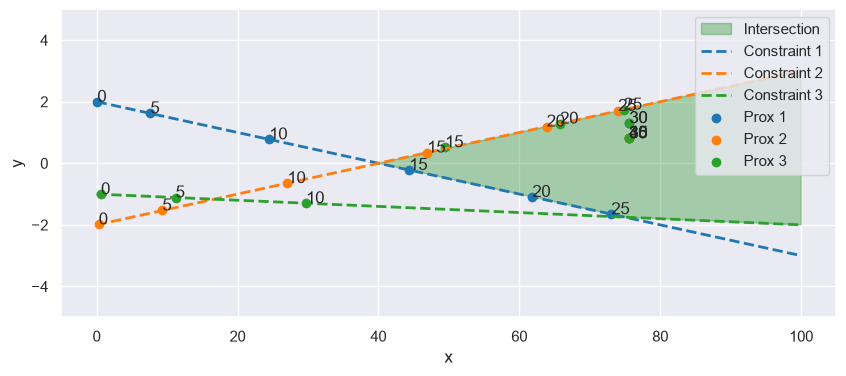

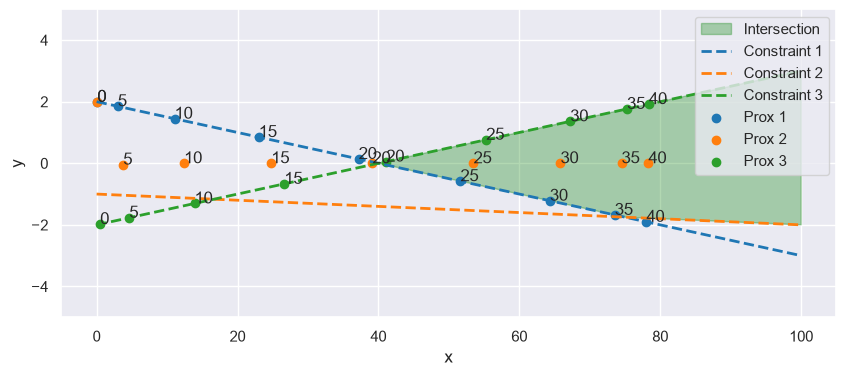

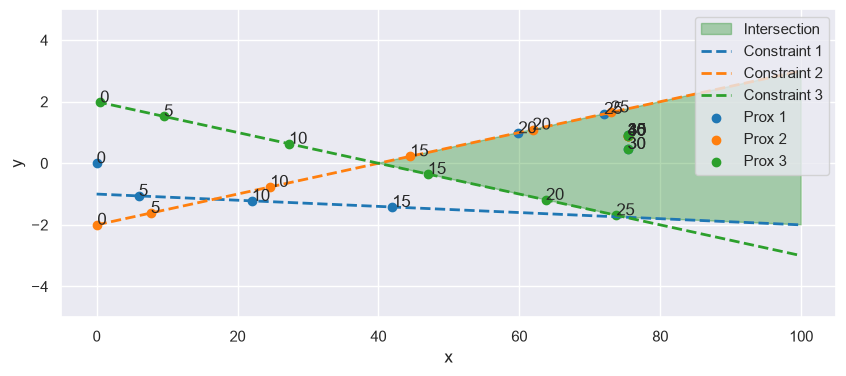

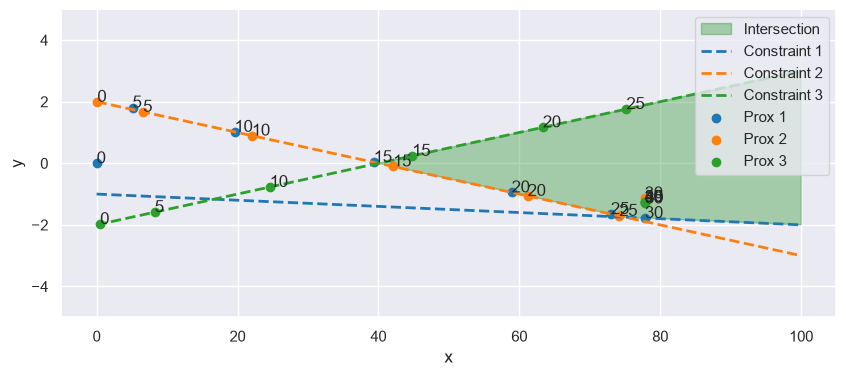

In [13]:

for ordering in [[0,2,1],[1,0,2],[1,2,0],[2,0,1],[2,1,0]]:
    print(ordering)
    c_ord = c[ordering]
    v_ord = v[ordering]
    data = [{'c':c_ord[i], 'v':v_ord[i],  'varlist':varlist} for i in range(n)]
    A = [halfspaceProj for _ in range(n)]
    cbpc_three = CbPlot(n)
    xbar, all_x, all_v = caraAlgorithm(data=data, A=A, W=Zs, Z=Zs, itrs=50, callback=cbpc_three, gamma=1.5, verbose=True)
    fig = plot_data(c_ord, v_ord, cbpc_three.data, ylim=(-5, 5), limit=41, stride=5)